# Практика 1. Полный цикл PyTorch и исчезающие градиенты

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "01_pytorch_practice"
OUT.mkdir(exist_ok=True, parents=True)

## Данные, Dataset и DataLoader

Два нелинейных класса, 1200 объектов, разбиение 60/20/20. Базовая модель — логистическая регрессия. Метрики: accuracy, macro-F1 и loss.

Batch: [(64, 2), (64,)]
Baseline validation accuracy: 0.45416666666666666


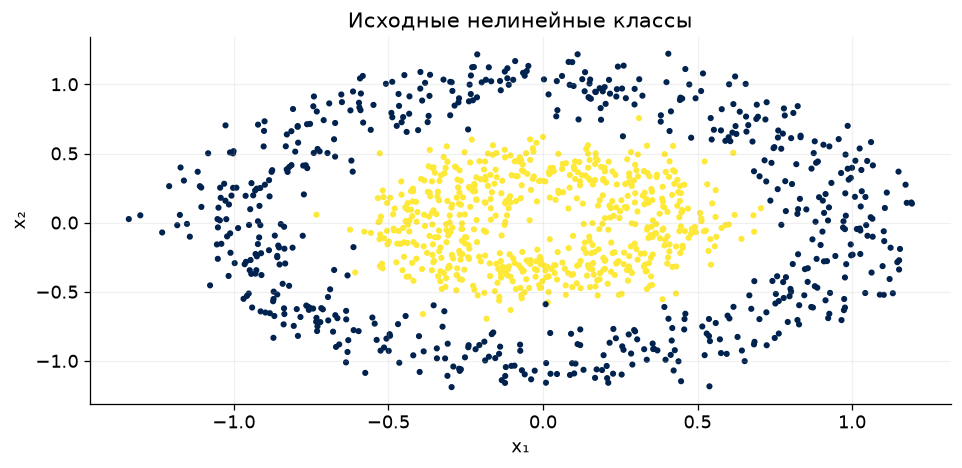

Custom Dataset model validation: {'accuracy': 0.9958333333333333, 'macro_f1': 0.9958332609941145}


In [2]:
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression

X, y = make_circles(1200, noise=0.12, factor=0.4, random_state=11)
train, val, test = split3(X, y)


class CircleDataset(Dataset):
    def __init__(self, data):
        self.x, self.y = data

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


loader = DataLoader(CircleDataset(train), batch_size=64, shuffle=True)
print("Batch:", [tuple(z.shape) for z in next(iter(loader))])
baseline = LogisticRegression().fit(train[0], train[1])
print("Baseline validation accuracy:", baseline.score(val[0], val[1]))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="cividis", s=8)
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("Исходные нелинейные классы")
showfig("data", OUT)

seed_all()
demo = MLP(2, 2, (32, 32))
optimizer = torch.optim.Adam(demo.parameters(), lr=0.01)
for epoch in range(15):
    demo.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(demo(xb), yb)
        loss.backward()
        optimizer.step()
print("Custom Dataset model validation:", classify(demo, val)[0])

## Общая часть. Активации, оптимизаторы, batch и early stopping

Исходная конфигурация: ReLU, Adam, batch = 64. Меняю по одному параметру при одинаковой инициализации. fit возвращает веса с лучшим validation loss.

,name,optimizer,activation,batch,accuracy,macro_f1,seconds,epochs,parameters
0,baseline,Adam,relu,64,0.99583,0.99583,0.08603,24,1218
1,tanh,Adam,tanh,64,1.00000,1.00000,0.18051,49,1218
2,sigmoid,Adam,sigmoid,64,0.99583,0.99583,0.20417,57,1218
3,SGD,SGD,relu,64,0.89583,0.89569,0.23849,80,1218
4,Momentum,Momentum,relu,64,0.99583,0.99583,0.24532,80,1218
5,batch16,Adam,relu,16,1.00000,1.00000,0.31155,31,1218
6,batch128,Adam,relu,128,0.99583,0.99583,0.08403,38,1218


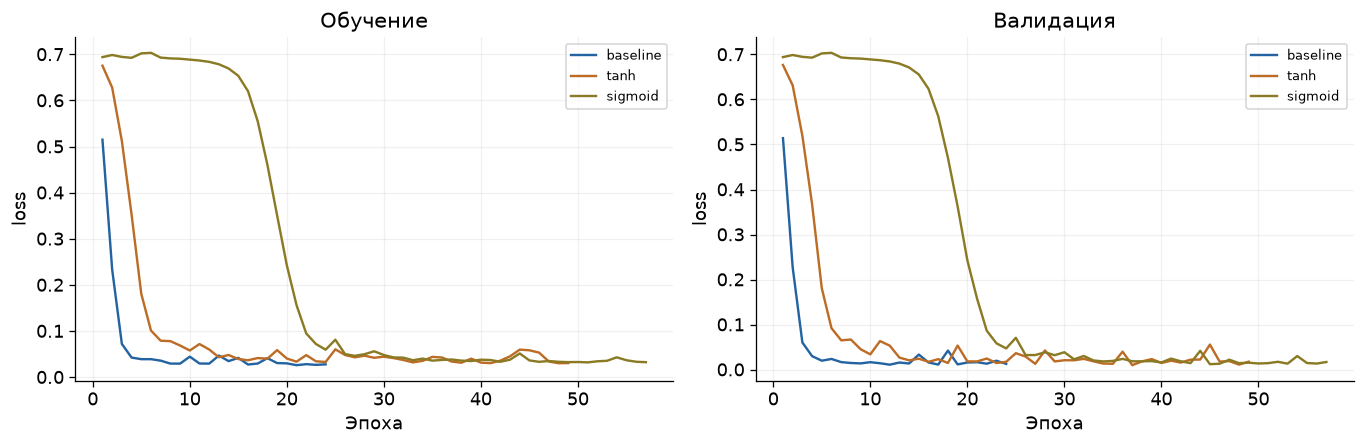

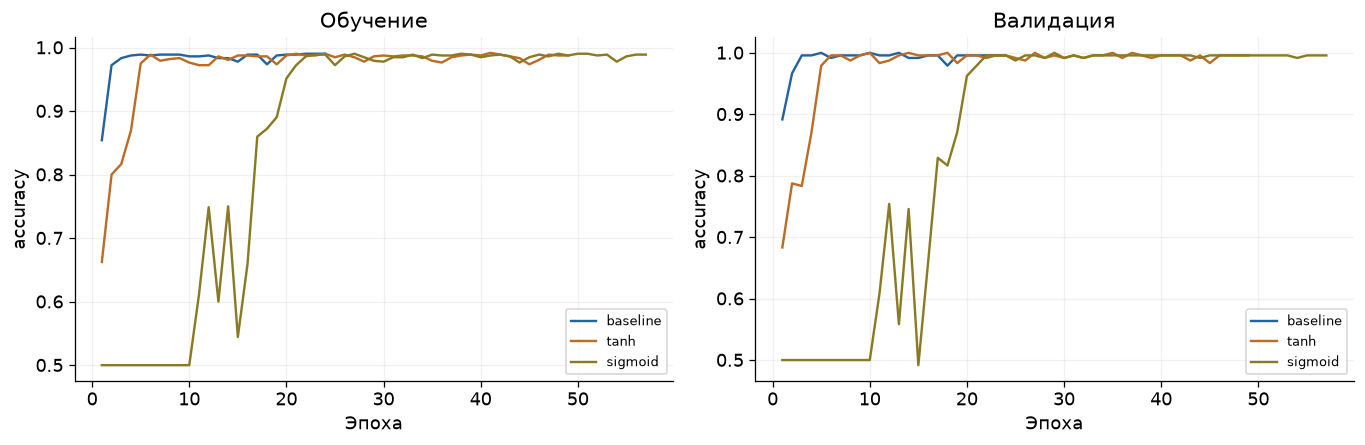

Выбрано по validation: tanh Test: {'accuracy': 0.9916666666666667, 'macro_f1': 0.9916660879227724}


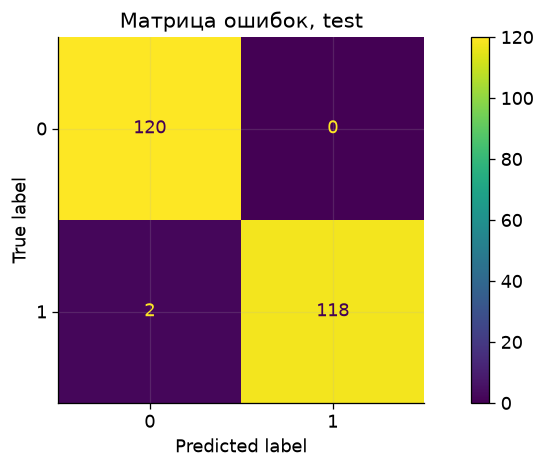

Inference: [[1.2748066e-06 9.9999869e-01]
 [9.9961627e-01 3.8375228e-04]]


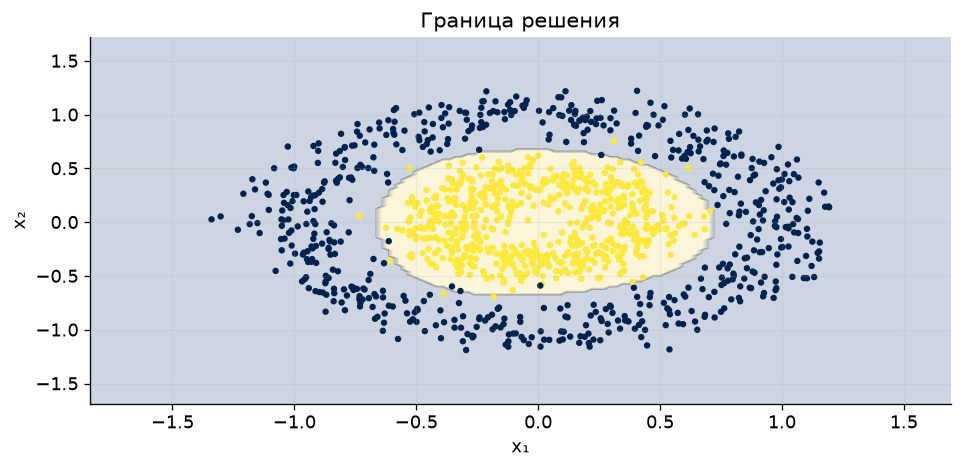

,index,true,predicted,confidence,probability_margin,analysis
0,163,1,0,0.64093,0.28185,Уверенная ошибка: проверить неоднозначность пр...
1,98,0,0,0.73608,0.47217,Верный ответ с малым отрывом от альтернативы
2,30,0,0,0.81159,0.62319,Верный ответ с малым отрывом от альтернативы
3,198,0,0,0.81550,0.63099,Верный ответ с малым отрывом от альтернативы
4,226,1,1,0.86246,0.72492,Верный ответ с малым отрывом от альтернативы
5,172,0,0,0.91516,0.83032,Верный ответ с малым отрывом от альтернативы
6,140,0,0,0.92273,0.84546,Верный ответ с малым отрывом от альтернативы
7,126,0,0,0.93834,0.87668,Верный ответ с малым отрывом от альтернативы
8,146,0,0,0.93892,0.87784,Верный ответ с малым отрывом от альтернативы
9,178,0,0,0.93999,0.87999,Верный ответ с малым отрывом от альтернативы


Наименее уверенные объекты (ошибок меньше заданного числа). Большая уверенность ошибочного ответа указывает на ограничение калибровки; близкие признаки классов усложняют границу.

Проверка checkpoint: tanh


Конфигурация tanh выбрана по validation; итоговая test accuracy=0.992. Early stopping останавливает обучение по validation loss, сохранённые веса относятся к её минимуму.

In [3]:
configs = [
    ("baseline", "relu", "Adam", 64),
    ("tanh", "tanh", "Adam", 64),
    ("sigmoid", "sigmoid", "Adam", 64),
    ("SGD", "relu", "SGD", 64),
    ("Momentum", "relu", "Momentum", 64),
    ("batch16", "relu", "Adam", 16),
    ("batch128", "relu", "Adam", 128),
]
rows = []
curves = {}
models = {}
for name, act, opt, bs in configs:
    seed_all()
    m = MLP(2, 2, (32, 32), activation=act)
    m, h, t = fit(
        m, train, val, epochs=80, batch=bs, lr=0.01, optimizer=opt, patience=12
    )
    metrics, _, _ = classify(m, val)
    rows.append(
        {
            "name": name,
            "optimizer": opt,
            "activation": act,
            "batch": bs,
            **metrics,
            "seconds": t,
            "epochs": len(h),
            "parameters": count_params(m),
        }
    )
    curves[name] = h
    models[name] = m
df = table(rows, OUT)
histories(dict(list(curves.items())[:3]), OUT)
histories(dict(list(curves.items())[:3]), OUT, "accuracy_curves", metric="accuracy")
best_name = df.sort_values(["macro_f1", "accuracy"], ascending=False).iloc[0]["name"]
best = models[best_name]
metrics, pred, p = classify(best, test)
print("Выбрано по validation:", best_name, "Test:", metrics)
ConfusionMatrixDisplay.from_predictions(test[1], pred)
plt.title("Матрица ошибок, test")
showfig("confusion", OUT)
print(
    "Inference:",
    best(torch.tensor([[0.0, 0.0], [1.0, 0.0]])).softmax(1).detach().numpy(),
)
boundary(best, X, y, OUT)
errors(best, test, OUT)
torch.save(
    {"model": best.state_dict(), "config": best_name}, OUT / "best_checkpoint.pt"
)
print(
    "Проверка checkpoint:",
    torch.load(OUT / "best_checkpoint.pt", weights_only=False)["config"],
)
note(
    f'Конфигурация {best_name} выбрана по validation; итоговая test accuracy={metrics["accuracy"]:.3f}. Early stopping останавливает обучение по validation loss, сохранённые веса относятся к её минимуму.'
)

## Вариант 11. Исчезающие градиенты

Sigmoid и ReLU в сети с восемью скрытыми слоями по 32 нейрона, пять парных seed. Нормы градиентов считаю на одном batch до и после обучения.

,seed,activation,accuracy,macro_f1
0,11,sigmoid,0.50000,0.33333
1,11,relu,0.99583,0.99583
2,12,sigmoid,0.50000,0.33333
3,12,relu,0.99583,0.99583
4,13,sigmoid,0.50000,0.33333
5,13,relu,0.99583,0.99583
6,14,sigmoid,0.50000,0.33333
7,14,relu,0.99583,0.99583
8,15,sigmoid,0.50000,0.33333
9,15,relu,1.00000,1.00000


,seed,activation,stage,layer,norm
0,11,sigmoid,before,1,0.00000
1,11,sigmoid,before,2,0.00000
2,11,sigmoid,before,3,0.00001
3,11,sigmoid,before,4,0.00003
4,11,sigmoid,before,5,0.00026
...,...,...,...,...,...
175,15,relu,after,5,0.04138
176,15,relu,after,6,0.03205
177,15,relu,after,7,0.03555
178,15,relu,after,8,0.02158


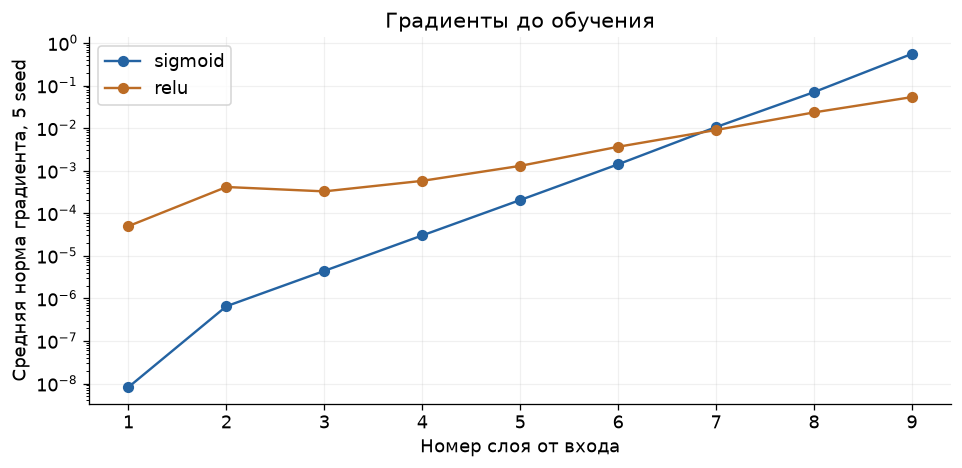

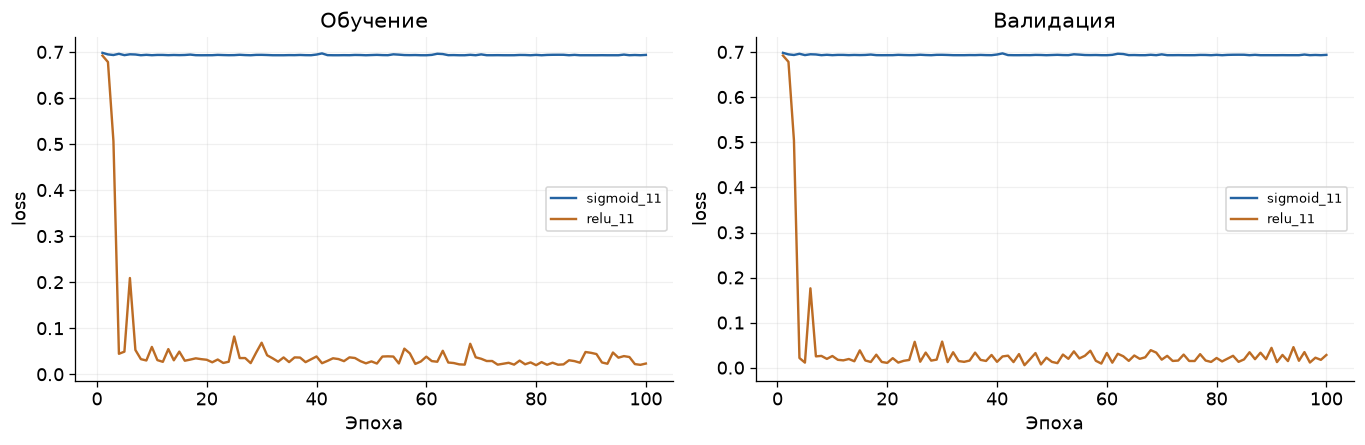

accuracy         macro_f1        
               mean     std     mean     std
activation                                  
relu         0.9967  0.0019   0.9967  0.0019
sigmoid      0.5000  0.0000   0.3333  0.0000

Производная Sigmoid не превышает 1/4: при последовательном перемножении якобианов ранние градиенты могут резко уменьшаться. ReLU сохраняет единичную производную на положительной части, но нулевая производная на отрицательной части создаёт риск неактивных нейронов. График показывает измеренные нормы; их масштаб зависит и от инициализации.

In [4]:
rows = []
gradrows = []
deepcurves = {}
for seed in [11, 12, 13, 14, 15]:
    for act in ["sigmoid", "relu"]:
        seed_all(seed)
        m = MLP(2, 2, (32,) * 8, activation=act)
        for stage in ["before", "after"]:
            if stage == "after":
                m, h, t = fit(m, train, val, epochs=100, lr=0.003, seed=seed)
                deepcurves[f"{act}_{seed}"] = h
            m.zero_grad()
            nn.functional.cross_entropy(m(train[0][:128]), train[1][:128]).backward()
            for layer, (name, p) in enumerate(
                (n, p) for n, p in m.named_parameters() if n.endswith("weight")
            ):
                gradrows.append(
                    {
                        "seed": seed,
                        "activation": act,
                        "stage": stage,
                        "layer": layer + 1,
                        "norm": p.grad.norm().item(),
                    }
                )
        metrics, _, _ = classify(m, val)
        rows.append({"seed": seed, "activation": act, **metrics})
df = table(rows, OUT, "vanishing_gradients_metrics")
g = table(gradrows, OUT, "gradient_norms")
for act in ["sigmoid", "relu"]:
    mean = (
        g[(g.activation == act) & (g.stage == "before")].groupby("layer")["norm"].mean()
    )
    plt.semilogy(mean.index, np.maximum(mean.values, 1e-12), "o-", label=act)
plt.xlabel("Номер слоя от входа")
plt.ylabel("Средняя норма градиента, 5 seed")
plt.title("Градиенты до обучения")
plt.legend()
showfig("gradient_layers", OUT)
histories(
    {k: v for k, v in deepcurves.items() if k.endswith("_11")}, OUT, "deep_curves"
)
display(
    df.groupby("activation")[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(4)
)
note(
    "Производная Sigmoid не превышает 1/4: при последовательном перемножении якобианов ранние градиенты могут резко уменьшаться. ReLU сохраняет единичную производную на положительной части, но нулевая производная на отрицательной части создаёт риск неактивных нейронов. График показывает измеренные нормы; их масштаб зависит и от инициализации."
)